In [1]:
import pandas as pd
import matplotlib.pyplot as plt

file_path = "GTEx_Analysis_2017-06-05_v8_RNASeQCv1.1.9_gene_median_tpm.txt"
df = pd.read_csv(file_path, sep='\t', skiprows=2)


print(df.shape)       
print(df.columns[:10]) 

(56200, 56)
Index(['Name', 'Description', 'Adipose - Subcutaneous',
       'Adipose - Visceral (Omentum)', 'Adrenal Gland', 'Artery - Aorta',
       'Artery - Coronary', 'Artery - Tibial', 'Bladder', 'Brain - Amygdala'],
      dtype='object')


In [2]:
muscle_cols = [col for col in df.columns if "Muscle - Skeletal" in col]
brain_cols = [col for col in df.columns if "Brain" in col]
liver_cols = [col for col in df.columns if "Liver" in col]

print("Muscle columns:", muscle_cols)
print("Brain columns:", brain_cols)
print("Liver columns:", liver_cols)

Muscle columns: ['Muscle - Skeletal']
Brain columns: ['Brain - Amygdala', 'Brain - Anterior cingulate cortex (BA24)', 'Brain - Caudate (basal ganglia)', 'Brain - Cerebellar Hemisphere', 'Brain - Cerebellum', 'Brain - Cortex', 'Brain - Frontal Cortex (BA9)', 'Brain - Hippocampus', 'Brain - Hypothalamus', 'Brain - Nucleus accumbens (basal ganglia)', 'Brain - Putamen (basal ganglia)', 'Brain - Spinal cord (cervical c-1)', 'Brain - Substantia nigra']
Liver columns: ['Liver']


In [3]:
df["Brain_Avg"] = df[brain_cols].mean(axis=1)

df_subset = df[["Name"] + muscle_cols + ["Brain_Avg"] + liver_cols].copy()  # <-- make a copy

df_subset.rename(columns={muscle_cols[0]: "Muscle", liver_cols[0]: "Liver"}, inplace=True)

df_subset.head()

,Name,Muscle,Brain_Avg,Liver
0,ENSG00000223972.5,0.00000,0.000000,0.00000
1,ENSG00000227232.5,1.41667,2.379063,1.76541
2,ENSG00000278267.1,0.00000,0.000000,0.00000
3,ENSG00000243485.5,0.00000,0.013877,0.00000
4,ENSG00000237613.2,0.00000,0.000000,0.00000


In [4]:
df_filtered = df_subset[
    (df_subset["Muscle"] > df_subset["Brain_Avg"]) & 
    (df_subset["Muscle"] > df_subset["Liver"])
]

print(f"Filtered genes: {df_filtered.shape[0]}")

top5_muscle = df_filtered.sort_values(by="Muscle", ascending=False).head(5)

top5_muscle = top5_muscle.merge(df[["Name", "Description"]], on="Name", how="left")
top5_muscle.rename(columns={"Description": "Gene_Symbol"}, inplace=True)
top5_muscle = top5_muscle[["Gene_Symbol", "Name", "Muscle", "Brain_Avg", "Liver"]]

Filtered genes: 6549


In [5]:
top5_muscle.to_csv("top5_muscle_vs_brain_liver.csv", index=False)

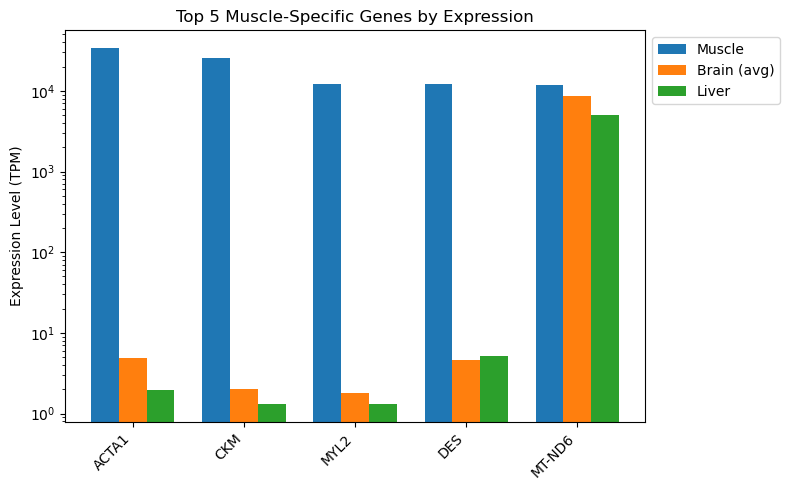

In [6]:
import numpy as np

genes = top5_muscle["Gene_Symbol"]
x = np.arange(len(genes))
width = 0.25

fig, ax = plt.subplots(figsize=(8, 5))

# Plot bars
ax.bar(x - width, top5_muscle["Muscle"], width, label="Muscle")
ax.bar(x, top5_muscle["Brain_Avg"], width, label="Brain (avg)")
ax.bar(x + width, top5_muscle["Liver"], width, label="Liver")

ax.set_ylabel("Expression Level (TPM)")
ax.set_title("Top 5 Muscle-Specific Genes by Expression")
ax.set_xticks(x)
ax.set_xticklabels(genes, rotation=45, ha="right")
ax.set_yscale("log") 

ax.legend(loc="upper left", bbox_to_anchor=(1, 1))

plt.subplots_adjust(top=0.85, right=0.75)

plt.tight_layout()
plt.show()

In [10]:
top5_muscle[["Gene_Symbol", "Muscle", "Brain_Avg", "Liver"]]

,Gene_Symbol,Muscle,Brain_Avg,Liver
0,ACTA1,33847.5,4.836232,1.96674
1,CKM,25785.6,2.013896,1.30496
2,MYL2,12092.5,1.791546,1.32416
3,DES,12069.4,4.629163,5.18058
4,MT-ND6,11686.1,8565.503846,5021.89000
